In [1]:
# Install Cohere for embeddings, Umap to reduce embeddings to 2 dimensions, Altair for visualization, Annoy for approximate nearest neighbor search
!pip install cohere umap-learn altair datasets tqdm tiktoken openai seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 370.7/370.7 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 49.1 MB/s eta 0:00:00


In [2]:
import cohere
import numpy as np
import re
import pandas as pd
from tqdm import tqdm
from datasets import load_dataset
import umap
import altair as alt
from sklearn.metrics.pairwise import cosine_similarity
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth', None)

In [ ]:
# Cohere api key
api_key = 'API_KEY'

co = cohere.Client(api_key)

In [4]:
qa_df = pd.DataFrame({'text':
                      [
                          'Where is the world cup?',
                          'The world cup is in Qatar',
                          'What color is the sky?',
                          'The sky is blue',
                          'Where does the bear live?',
                          'The bear lives in the woods',
                          'What is an apple?',
                          'An apple is a fruit',
                      ]})

qa_df

,text
0,Where is the world cup?
1,The world cup is in Qatar
2,What color is the sky?
3,The sky is blue
4,Where does the bear live?
5,The bear lives in the woods
6,What is an apple?
7,An apple is a fruit


In [5]:
# A function that classifies a list of inputs given the examples
def embed_text(texts):
  """
  Turns a piece of text into embeddings
  Arguments:
    text(str): the text to be turned into embeddings
  Returns:
    embedding(list): the embeddings
  """
  # Embed text by calling the Embed endpoint
  output = co.embed(
      model="embed-english-v3.0",
      input_type="search_document",
      texts=texts)
  embedding = output.embeddings

  return embedding

In [6]:
qa = embed_text(texts=list(qa_df['text']))

In [8]:
# Umap reduces dimensions from 1024 to 2 dimensions that we can plot
reducer = umap.UMAP(n_neighbors=2)
umap_embeds = reducer.fit_transform(qa)
# prepare the data to plot and interactive visualization
# using Altair
df_explore = qa_df
df_explore['x'] = umap_embeds[:,0]
df_explore['y'] = umap_embeds[:,1]

# Plot
chart = alt.Chart(df_explore).mark_circle(size=60).encode(
    x=#'x',
    alt.X('x', scale=alt.Scale(zero=False)),
    y=#'y',
    alt.Y('y', scale=alt.Scale(zero=False)),
    tooltip=['text']
).properties(
    width=700,
    height=400
)
chart.interactive()

alt.Chart(...)

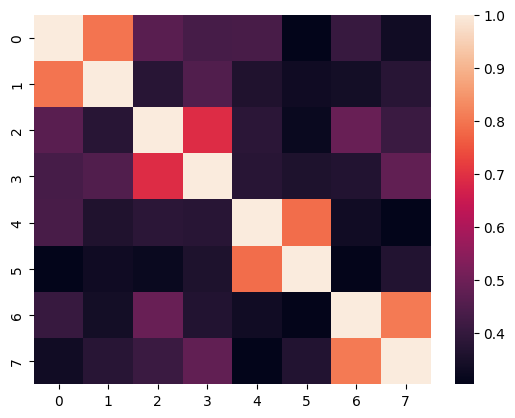

In [12]:
import seaborn as sb

def plot_similarities(data, embedding):
  similarities = []

  for i in range(len(data)):
    similarities.append([])
    for j in range(len(data)):
      similarities[-1].append(cosine_similarity(np.array([embedding[i]]), np.array([embedding[j]])))

  similarities = np.array(similarities).squeeze()

  sb.heatmap(similarities)

plot_similarities(qa_df, qa)